# 03-final: covariance change points in every scan

One notebook from data to results. For each scan it finds abrupt changes in the
105-network covariance, then runs the same pipeline on no-change copies to show
the false-alarm rate. For each change it lists which connections changed.

**To run:** attach the data, then Save & Run All (about 10-15 minutes on CPU).
Everything prints here. No other notebook is needed.

In [1]:
import os

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
from joblib import Parallel, delayed
from scipy import stats
from matplotlib.colors import LinearSegmentedColormap

SEED = 20261031
INPUT_ROOT = Path(os.environ.get("DFCPD_INPUT", "/kaggle/input"))
ALPHA, L, COPIES, MIN_SEGMENT, GUARD, ESS = 0.05, 5, 99, 120, 5, 0.71
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#6f6e69"
DIV = LinearSegmentedColormap.from_list("div", ["#184f95", "#6da7ec", "#f0efec", "#ec8a8a", "#b52f2f"])
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "font.size": 9})

## Load scans

Exact copies are dropped. Each scan is z-scored, which removes the mixed scaling.

In [2]:
def zscore(x):
    return (x - x.mean(0)) / x.std(0, ddof=1)


SCANS, GROUP, seen = {}, {}, set()
for path in sorted(INPUT_ROOT.rglob("icn_tc.npy")):
    x = zscore(np.load(path).astype(np.float64))
    key = hashlib.sha1(x.round(4).tobytes()).hexdigest()
    if key not in seen:
        seen.add(key)
        SCANS[path.parent.name] = x
        GROUP[path.parent.name] = path.parent.parent.name
assert SCANS, "attach the data"
print(len(SCANS), "scans")

781 scans


## Detector

The statistic is Li & Li's whole-scan covariance change statistic. A scan's
p-value compares it with no-change copies that keep the scan's spectrum and its
slow variance trend. A significant scan is split at the best point and each side
is tested again, so one scan can have several change points.

In [3]:
def profile(x):
    n = len(x)
    g = (x @ x.T) ** 2
    i, j = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    g[np.abs(i - j) < L + 1] = 0
    c = np.zeros((n + 1, n + 1))
    c[1:, 1:] = g.cumsum(0).cumsum(1)
    t = np.arange(L + 2, n - L - 1)
    left, cross = c[t, t], c[t, n] - c[t, t]
    right = c[n, n] - c[t, n] - c[n, t] + left
    value = (left / ((t - L) * (t - L - 1)) + right / ((n - t - L) * (n - t - L - 1))
             - 2 * cross / (t * (n - t) - L * (L + 1) / 2))
    return t, (t - L) * (n - t - L) * value


def statistic(x):
    return profile(x)[1].sum() / len(x) ** 2


def scale_trend(x, bandwidth=60.0):
    energy = (x ** 2).mean(1)
    gap = np.arange(len(x))[None, :] - np.arange(len(x))[:, None]
    k = np.exp(-.5 * (gap / bandwidth) ** 2)
    s0, s1, s2 = k.sum(1), (k * gap).sum(1), (k * gap ** 2).sum(1)
    smooth = np.clip((s2 * (k @ energy) - s1 * ((k * gap) @ energy)) / (s0 * s2 - s1 ** 2), .05 * energy.mean(), None)
    return np.sqrt(smooth / smooth.mean())


def no_change_copy(x, rng):
    s = scale_trend(x)
    flat = zscore(x / s[:, None])
    spectrum = np.fft.rfft(flat, axis=0)
    phases = np.exp(2j * np.pi * rng.random(spectrum.shape[0]))
    phases[0] = 1
    if len(x) % 2 == 0:
        phases[-1] = rng.choice((-1.0, 1.0))
    return zscore(np.fft.irfft(spectrum * phases[:, None], n=len(x), axis=0) * s[:, None])


def p_value(x, rng):
    observed = statistic(x)
    return (1 + sum(statistic(no_change_copy(x, rng)) >= observed for _ in range(COPIES))) / (COPIES + 1)


def detect(x, rng):
    found, first = [], []

    def recurse(start, stop):
        if stop - start < MIN_SEGMENT:
            return
        segment = zscore(x[start:stop])
        p = p_value(segment, rng)
        first.append(p)
        if p > ALPHA:
            return
        t, values = profile(segment)
        tau = start + int(np.clip(t[np.argmax(values)], MIN_SEGMENT // 2, len(segment) - MIN_SEGMENT // 2))
        found.append(tau)
        recurse(start, tau)
        recurse(tau, stop)

    recurse(0, len(x))
    return sorted(found), first[0] if first else np.nan


def run_scan(sid, x, seed):
    rng = np.random.default_rng(seed)
    points, p = detect(x, rng)
    null_points, null_p = detect(no_change_copy(x, rng), rng)
    return {"scan": sid, "group": GROUP[sid], "T": len(x), "change_points": points, "p": p,
            "null_change_points": null_points, "null_p": null_p}

## Run on every scan

In [4]:
rows = Parallel(n_jobs=os.cpu_count() or 1, verbose=5)(
    delayed(run_scan)(sid, x, SEED + k) for k, (sid, x) in enumerate(SCANS.items()))
table = pd.DataFrame(rows)
table["K"] = table["change_points"].map(len)
table["null_K"] = table["null_change_points"].map(len)
table.drop(columns=["change_points", "null_change_points"]).to_csv("scan_results.csv", index=False)

real, null = (table["K"] > 0).mean(), (table["null_K"] > 0).mean()
se = np.sqrt(null * (1 - null) / len(table))
summary = {"scans": len(table), "share_with_change_real": round(real, 3), "share_with_change_no_change_copies": round(null, 3),
           "copies_2se": round(2 * se, 3), "target_false_alarm": ALPHA,
           "K_counts_real": table["K"].value_counts().sort_index().to_dict(),
           "K_counts_copies": table["null_K"].value_counts().sort_index().to_dict()}
print(json.dumps(summary, indent=1, default=int))

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    7.6s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   32.3s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  1.2min
[Parallel(n_jobs=4)]: Done 280 tasks      | elapsed:  2.3min
[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed:  3.3min
[Parallel(n_jobs=4)]: Done 640 tasks      | elapsed:  4.6min


{
 "scans": 781,
 "share_with_change_real": 0.279,
 "share_with_change_no_change_copies": 0.029,
 "copies_2se": 0.012,
 "target_false_alarm": 0.05,
 "K_counts_real": {
  "0": 563,
  "1": 177,
  "2": 41
 },
 "K_counts_copies": {
  "0": 758,
  "1": 21,
  "2": 2
 }
}


[Parallel(n_jobs=4)]: Done 781 out of 781 | elapsed:  5.5min finished


## Which connections changed?

For each change, every edge is compared between the segments on either side,
with a few volumes skipped around the change. The Benjamini-Hochberg rule at 5%
gives the changed edges, using an effective sample size of 71% of the volumes.

In [5]:
UPPER = np.triu_indices(next(iter(SCANS.values())).shape[1], 1)
P = next(iter(SCANS.values())).shape[1]


def changed_edges(x, points):
    edges = [0] + points + [len(x)]
    out = []
    for k, tau in enumerate(points):
        a, b = x[edges[k]:tau - GUARD], x[tau + GUARD:edges[k + 2]]
        z_a = np.arctanh(np.clip(np.corrcoef(a.T)[UPPER], -.9999, .9999))
        z_b = np.arctanh(np.clip(np.corrcoef(b.T)[UPPER], -.9999, .9999))
        se_z = np.sqrt(1 / (ESS * len(a) - 3) + 1 / (ESS * len(b) - 3))
        p = 2 * stats.norm.sf(np.abs(z_b - z_a) / se_z)
        order = np.argsort(p)
        passed = p[order] <= ALPHA * np.arange(1, p.size + 1) / p.size
        n = int(np.flatnonzero(passed).max() + 1) if passed.any() else 0
        hits = np.zeros(p.size, bool)
        hits[order[:n]] = True
        out.append((hits, z_b - z_a))
    return out


frequency = np.zeros(UPPER[0].size)
change_size = []
total = 0
for sid, points in zip(table["scan"], table["change_points"]):
    for hits, diff in changed_edges(SCANS[sid], points):
        frequency += hits
        change_size.append(hits.sum())
        total += 1
print("changes:", total, "| median edges changed per change:", int(np.median(change_size)) if change_size else 0,
      "of", UPPER[0].size, "| share of changes with any edge:", round(float(np.mean(np.array(change_size) > 0)), 3) if change_size else 0)

changes: 259 | median edges changed per change: 119 of 5460 | share of changes with any edge: 0.873


## Figures

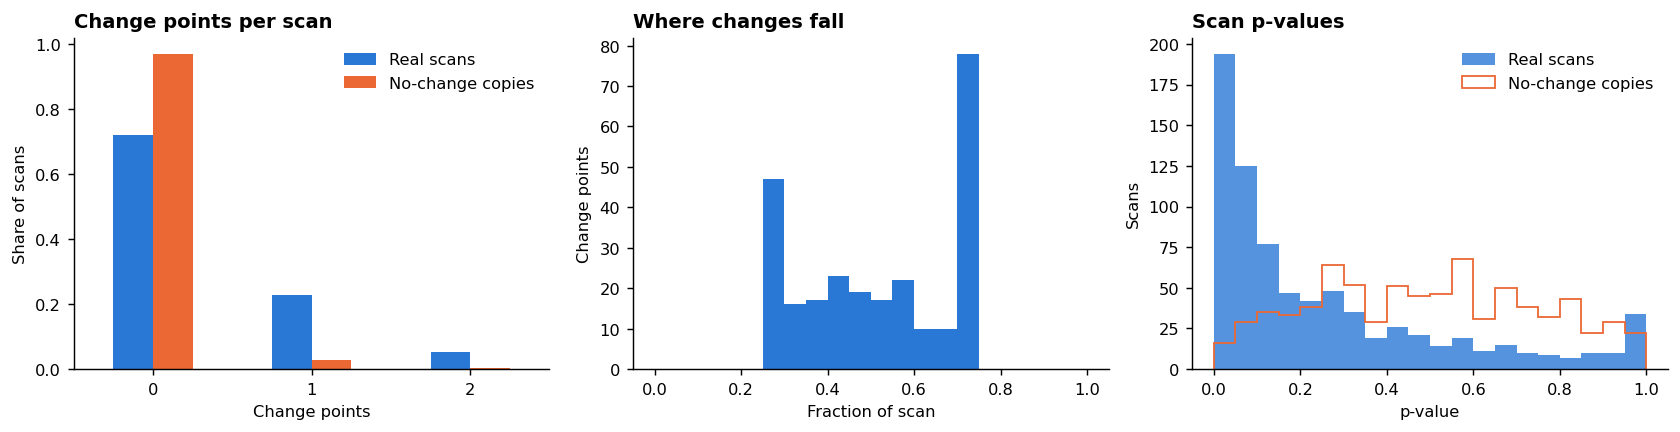

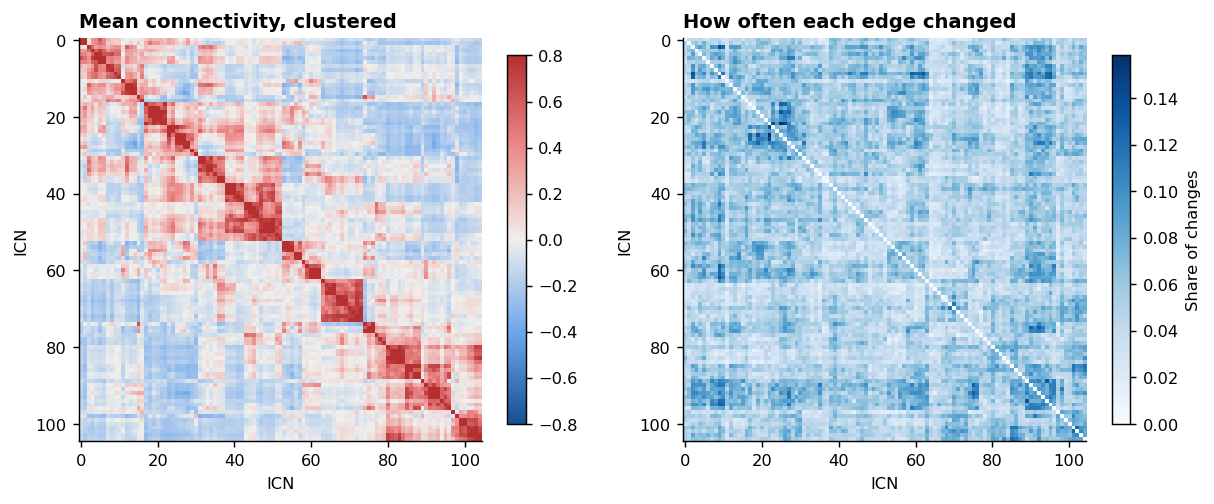

 icn_a  icn_b  share_of_changes
    32     55             0.158
    55     88             0.143
    55     62             0.139
   102    105             0.139
     4     32             0.135
    58    102             0.135
    16     66             0.135
    17     24             0.131
    53    102             0.131
     7     24             0.131


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
counts = pd.DataFrame({"Real scans": table["K"].value_counts(normalize=True),
                       "No-change copies": table["null_K"].value_counts(normalize=True)}).fillna(0).sort_index()
counts.plot.bar(ax=axes[0], color=[BLUE, ORANGE], rot=0)
axes[0].set(title="Change points per scan", xlabel="Change points", ylabel="Share of scans")
axes[0].legend(frameon=False)
fractions = [t / T for points, T in zip(table["change_points"], table["T"]) for t in points]
axes[1].hist(fractions, bins=20, range=(0, 1), color=BLUE)
axes[1].set(title="Where changes fall", xlabel="Fraction of scan", ylabel="Change points")
axes[2].hist(table["p"], bins=20, range=(0, 1), color=BLUE, alpha=.8, label="Real scans")
axes[2].hist(table["null_p"], bins=20, range=(0, 1), histtype="step", color=ORANGE, lw=2, label="No-change copies")
axes[2].set(title="Scan p-values", xlabel="p-value", ylabel="Scans")
axes[2].legend(frameon=False)
fig.tight_layout()
plt.show()

mean_r = np.mean([np.corrcoef(x.T) for x in SCANS.values()], axis=0)
order = sch.leaves_list(sch.linkage(1 - mean_r[UPPER], method="average"))
matrix = np.zeros((P, P))
matrix[UPPER] = frequency / max(total, 1)
matrix = matrix + matrix.T
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
image = axes[0].imshow(mean_r[np.ix_(order, order)], cmap=DIV, vmin=-.8, vmax=.8)
axes[0].set(title="Mean connectivity, clustered", xlabel="ICN", ylabel="ICN")
fig.colorbar(image, ax=axes[0], shrink=.8)
image = axes[1].imshow(matrix[np.ix_(order, order)], cmap="Blues")
axes[1].set(title="How often each edge changed", xlabel="ICN", ylabel="ICN")
fig.colorbar(image, ax=axes[1], shrink=.8, label="Share of changes")
plt.show()

if total:
    top = np.argsort(-frequency)[:10]
    print(pd.DataFrame({"icn_a": UPPER[0][top] + 1, "icn_b": UPPER[1][top] + 1,
                        "share_of_changes": (frequency[top] / total).round(3)}).to_string(index=False))

## By group (descriptive only)

Not a diagnostic result. Scan length differs between groups, so T is shown too.

In [7]:
print(table.groupby("group").agg(scans=("K", "size"), share_with_change=("K", lambda v: (v > 0).mean()),
                                 mean_K=("K", "mean"), median_T=("T", "median")).round(3).to_string())

       scans  share_with_change  mean_K  median_T
group                                            
BP       182              0.286   0.335     210.0
SZ       286              0.273   0.318     230.0
test     313              0.281   0.342     230.0
